# 3장 2강: 규제 — L1(Lasso), L2(Ridge), ElasticNet

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 Ridge, Lasso, ElasticNet 규제가 회귀계수와 일반화 성능에 어떤 영향을 주는지 확인합니다.

- 규제가 계수의 크기를 줄이는 이유를 이해합니다.
- `alpha` 변화에 따라 Ridge의 계수 크기와 Test 성능이 어떻게 달라지는지 확인합니다.
- Lasso가 일부 계수를 정확히 0으로 만드는지 확인합니다.
- ElasticNet이 L1과 L2를 함께 사용하는 모델이라는 점을 확인합니다.
- Ridge / Lasso / ElasticNet의 계수와 Test 성능을 비교합니다.

> 이 실습에서는 3장 2강 교안에서 다룬 규제, alpha, Lasso, Ridge, ElasticNet, StandardScaler, R² 비교만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- numpy
- matplotlib
- scikit-learn
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

### 사용할 특성

규제에 따른 계수 변화를 비교하기 위해 결측치가 없는 숫자형 특성 중 다음 12개를 사용합니다.

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `GarageArea`
- `TotalBsmtSF`
- `1stFlrSF`
- `2ndFlrSF`
- `FullBath`
- `TotRmsAbvGrd`
- `YearBuilt`
- `YearRemodAdd`
- `Fireplaces`

예측 대상은 `SalePrice`입니다.

## 실습 준비

규제는 계수의 크기를 기준으로 벌점을 주기 때문에 특성의 스케일을 맞추는 과정이 중요합니다.

이번 실습에서는 다음 순서로 데이터를 준비합니다.

1. Ames Housing 데이터 불러오기
2. 사용할 특성과 `SalePrice` 선택
3. Train / Test 분리
4. `StandardScaler`를 이용한 특성 표준화

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "YearRemodAdd",
    "Fireplaces"
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train 크기:", X_train_scaled.shape)
print("Test 크기:", X_test_scaled.shape)

Train 크기: (1168, 12)
Test 크기: (292, 12)


---

# 필수 1. Ridge와 alpha에 따른 계수 축소

## 배경

Ridge는 **L2 규제**를 사용합니다.

Ridge는 계수의 제곱합에 벌점을 주기 때문에 큰 계수를 더 강하게 억제하고, 모든 계수를 0에 가깝게 줄이는 특징이 있습니다.

## 문제 1. 여러 alpha 값에서 Ridge를 비교하세요.

### 요구사항

다음 alpha 값을 사용합니다.

```python
alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]
```

각 alpha에 대해 다음을 수행합니다.

1. `Ridge(alpha=alpha)` 모델을 만듭니다.
2. Train 데이터로 학습합니다.
3. Test 데이터를 예측합니다.
4. Test R²를 계산합니다.
5. `abs(model.coef_).sum()`으로 전체 계수 크기를 확인합니다.
6. 결과를 DataFrame으로 정리합니다.

### 확인 포인트

- alpha가 커질수록 규제 강도가 강해지는가?
- alpha가 커질수록 전체 계수 크기가 작아지는가?
- alpha가 너무 커지면 Test 성능이 낮아질 수 있는가?

,alpha,test_r2,coef_abs_sum
0,0.001,0.799357,102172.590850
1,0.010,0.799357,102172.463666
2,0.100,0.799355,102171.096834
3,1.000,0.799331,102149.831747
4,10.000,0.799056,101725.431454
5,100.000,0.795593,97390.120153


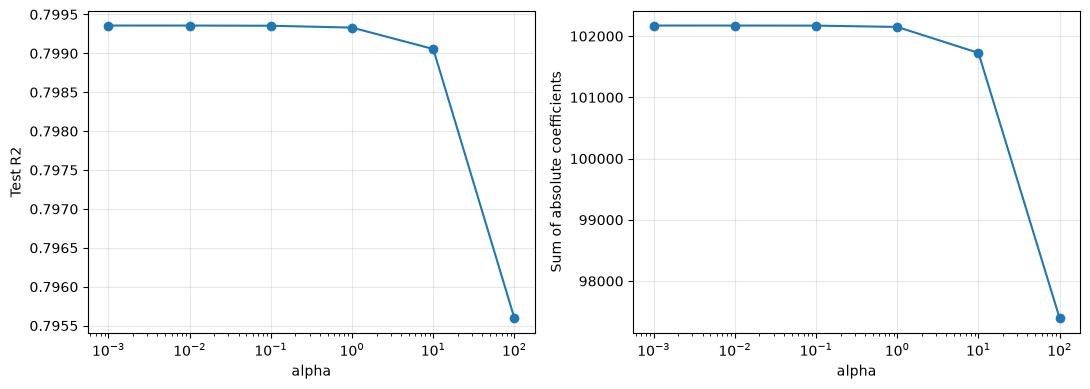

In [2]:
alpha_values = [0.001,0.01,0.1,1,10,100]
ridge_rows = []
for alpha in alpha_values:
    ridge_model = Ridge(alpha=alpha).fit(X_train_scaled,y_train)
    ridge_rows.append({'alpha':alpha,'test_r2':r2_score(y_test,ridge_model.predict(X_test_scaled)),
        'coef_abs_sum':abs(ridge_model.coef_).sum()})
ridge_df = pd.DataFrame(ridge_rows)
display(ridge_df)
fig,axes = plt.subplots(1,2,figsize=(11,4))
axes[0].semilogx(ridge_df['alpha'],ridge_df['test_r2'],'o-'); axes[0].set_ylabel('Test R2')
axes[1].semilogx(ridge_df['alpha'],ridge_df['coef_abs_sum'],'o-'); axes[1].set_ylabel('Sum of absolute coefficients')
for ax in axes: ax.set_xlabel('alpha'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Q1. alpha가 커질수록 Ridge 계수는 일반적으로 어떻게 변하나요?

**답변:**  
L2 벌점이 강해져 계수 벡터의 크기가 일반적으로 줄어듭니다. 이번 절댓값 합은 alpha=0.001의 102,172.59에서 alpha=100의 97,390.12로 감소합니다. 상관된 특성의 개별 계수나 절댓값 합이 항상 단조 감소하는 것은 아니고, Ridge는 보통 정확한 0을 만들지는 않습니다.

### Q2. alpha가 너무 크면 어떤 문제가 발생할 수 있나요?

**답변:**  
계수를 지나치게 억제하여 유용한 신호까지 잃고 고편향·과소적합이 발생할 수 있습니다. 다만 이번 alpha 후보에서는 Test 점수가 개선될 수 있으므로 과도한 규제로 성능이 나빠지는 현상이 반드시 관측되는 것은 아닙니다. 실제 alpha 선택은 Train 내부 검증으로 합니다.

---

# 필수 2. Lasso와 ElasticNet의 계수 변화

## 문제 1. Lasso에서 0이 되는 계수를 확인하세요.

### 배경

Lasso는 **L1 규제**를 사용하며, 중요하지 않은 특성의 계수를 정확히 0으로 만들 수 있습니다.

이번에는 규제 강도를 충분히 높여 Lasso의 변수 선택 효과를 직접 확인합니다.

### 요구사항

1. `Lasso(alpha=1000, max_iter=10000)` 모델을 만듭니다.
2. Train 데이터로 학습합니다.
3. 각 특성의 계수를 DataFrame으로 만듭니다.
4. 계수가 0인 특성의 개수를 계산합니다.
5. Test R²를 계산합니다.

### 확인 포인트

- 일부 계수가 정확히 0이 되는가?
- Ridge와 달리 Lasso가 변수 선택 효과를 갖는 이유를 이해했는가?

In [3]:
lasso_model = Lasso(alpha=1000,max_iter=10000).fit(X_train_scaled,y_train)
lasso_coef_df = pd.DataFrame({'feature':features,'coefficient':lasso_model.coef_})
lasso_zero_count = int((lasso_model.coef_ == 0).sum())
lasso_r2 = r2_score(y_test,lasso_model.predict(X_test_scaled))
display(lasso_coef_df)
print('정확히 0인 계수 수:',lasso_zero_count)
print('Test R2:',lasso_r2)

,feature,coefficient
0,OverallQual,25520.693859
1,GrLivArea,21419.631042
2,GarageCars,6820.209072
3,GarageArea,4370.090292
4,TotalBsmtSF,7305.573442
5,1stFlrSF,3521.096689
6,2ndFlrSF,0.000000
7,FullBath,-0.000000
8,TotRmsAbvGrd,83.200163
9,YearBuilt,6966.923170


정확히 0인 계수 수: 2
Test R2: 0.7960182963880562


### Q3. Lasso에서 계수가 0이 된다는 것은 어떤 의미인가요?

**답변:**  
이번 모델에서는 2ndFlrSF, FullBath의 계수가 정확히 0이 되어 예측식에서 제외됩니다(2개). 이는 해당 규제 강도와 다른 입력 특성을 함께 고려한 결과이며, 그 특성이 실제로 중요하지 않거나 인과적 영향이 없다는 뜻은 아닙니다.

## 문제 2. ElasticNet을 학습하고 L1/L2 혼합을 확인하세요.

### 배경

ElasticNet은 L1과 L2 규제를 함께 사용합니다.

`l1_ratio`는 두 규제의 비율을 조절합니다.

- `l1_ratio`가 1에 가까움 → Lasso 성격이 강함
- `l1_ratio`가 0에 가까움 → Ridge 성격이 강함

### 요구사항

1. `ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)` 모델을 만듭니다.
2. Train 데이터로 학습합니다.
3. Test R²를 계산합니다.
4. 각 특성의 계수를 확인합니다.

### 확인 포인트

- `alpha`와 `l1_ratio`의 역할을 구분할 수 있는가?
- ElasticNet이 Lasso와 Ridge의 성격을 함께 가진다는 점을 설명할 수 있는가?

In [4]:
elastic_model = ElasticNet(alpha=.1,l1_ratio=.5,max_iter=10000).fit(X_train_scaled,y_train)
elastic_r2 = r2_score(y_test,elastic_model.predict(X_test_scaled))
display(pd.DataFrame({'feature':features,'coefficient':elastic_model.coef_}))
print('Test R2:',elastic_r2)

,feature,coefficient
0,OverallQual,23514.629015
1,GrLivArea,12670.768121
2,GarageCars,6785.127803
3,GarageArea,5137.437024
4,TotalBsmtSF,8016.089858
5,1stFlrSF,9237.815373
6,2ndFlrSF,6873.818086
7,FullBath,-1895.877032
8,TotRmsAbvGrd,2541.484569
9,YearBuilt,8072.285509


Test R2: 0.7972913023796784


### Q4. `alpha`와 `l1_ratio`는 각각 무엇을 조절하나요?

**답변:**  
alpha는 전체 규제 강도를, l1_ratio는 L1과 L2의 혼합 비율을 조절합니다. l1_ratio=0.5이면 벌점식에서 L1 비중 0.5와 L2 비중 0.5를 사용하며, 실제 두 벌점의 수치가 동일하다는 뜻은 아닙니다.

---

# 과제 1. 다중공선성 진단과 Ridge / Lasso / ElasticNet 비교

## 배경

같은 Train/Test 데이터에서 세 규제 모델을 비교합니다. 성취도 평가항목에 맞춰, 비교 전에 **다중공선성의 계수 해석 영향과 VIF 진단·처치 선택**을 추가합니다.

다중공선성은 입력 특성들이 서로 강한 선형 관계를 갖는 상황입니다. VIF는 한 특성을 나머지 특성으로 설명할 때 구한 결정계수 R²를 이용해 `1 / (1 - R²)`로 계산합니다. 이때 예측 대상은 `SalePrice`가 아니라 **진단할 입력 특성 하나**이며, 보조 회귀에는 절편을 포함합니다.

## 요구사항

### A. 다중공선성 진단과 처치 방향 선택

1. **Train의 입력 특성만** 이용해 특성별 VIF를 계산하고 내림차순 표 `vif_df`를 출력합니다. 기존 `X_train_scaled`를 사용해도 됩니다. 표준화는 특성 간 선형 관계 자체를 제거하지 않습니다.
2. 이번 과제에서는 `VIF < 5`: 상대적으로 낮음, `5 ≤ VIF < 10`: 주의, `VIF ≥ 10`: 높은 수준으로 분류합니다. 이는 절대적 삭제 규칙이 아닌 실습용 판단 기준입니다.
3. 주의·높은 수준인 특성을 특성명과 VIF로 제시합니다. 없으면 없다고 작성합니다. 완전한 선형 중복으로 VIF가 무한대인 경우 높은 수준으로 해석합니다. 상수 특성의 VIF는 정의하기 어려우므로 별도로 표시합니다.
4. 다중공선성이 계수의 크기·부호·안정성과 개별 변수 해석에 미치는 영향을 설명합니다.
5. 특성의 의미와 VIF 결과를 근거로 **변수 제거·결합·규제 중 한 가지 처치 방향**을 선택하고 대상·이유·한계를 설명합니다. 높은 VIF가 없으면 불필요한 제거를 하지 않는 이유와 기존 규제 비교의 목적을 설명해도 됩니다. 제거·결합의 추가 구현은 요구하지 않습니다.

### B. 기존 규제 모델 비교

다음 설정을 그대로 사용합니다.

```python
Ridge(alpha=1.0)
Lasso(alpha=1000, max_iter=10000)
ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
```

1. 세 모델을 동일한 표준화 Train 데이터로 학습합니다.
2. 동일한 Test 데이터의 R²를 계산합니다.
3. 전체 계수 크기 `abs(coef_).sum()`과 계수가 정확히 0인 개수를 계산합니다.
4. 결과를 `comparison_df`로 정리하고, 특성별 계수를 `task_coef_df`로 출력합니다.
5. Test R²와 계수 처리 차이를 함께 설명하고 Q5~Q9에 답합니다.

> Test 점수는 지정된 세 설정의 결과를 비교·해석하는 데 사용합니다. 이 점수를 보고 변수를 제거하거나 alpha를 반복 조정하지 않습니다. 실제 모델 선택·튜닝에는 Train 내부 검증 또는 CV가 필요합니다.

### 확인 포인트

- Train 입력 특성만 사용하여 VIF를 계산했는가?
- 기준과 실제 수치를 근거로 주의할 특성을 판단했는가?
- 다중공선성의 계수 해석 영향과 처치 선택 이유를 설명했는가?
- 규제가 입력 특성의 VIF 자체를 낮추는 것은 아님을 구분했는가?
- 같은 데이터에서 세 모델의 Test R²·계수 크기·0 계수 개수를 비교했는가?


In [6]:
from sklearn.linear_model import LinearRegression
vif_rows = []
for j,feature in enumerate(features):
    target_feature = X_train_scaled[:,j]
    if np.ptp(target_feature) == 0:
        vif,level = np.nan,'상수: 정의 어려움'
    else:
        other_features = np.delete(X_train_scaled,j,axis=1)
        auxiliary = LinearRegression(fit_intercept=True).fit(other_features,target_feature)
        auxiliary_r2 = auxiliary.score(other_features,target_feature)
        vif = np.inf if 1-auxiliary_r2 <= np.finfo(float).eps else 1/(1-auxiliary_r2)
        level = '높은 수준' if vif >= 10 else '주의' if vif >= 5 else '상대적으로 낮음'
    vif_rows.append({'feature':feature,'VIF':vif,'level':level})
vif_df = pd.DataFrame(vif_rows).sort_values('VIF',ascending=False).reset_index(drop=True)
display(vif_df)
print('주의·높은 수준 특성:')
display(vif_df[vif_df['VIF']>=5])
task_models = {'Ridge':Ridge(alpha=1.0), 'Lasso':Lasso(alpha=1000,max_iter=10000),
    'ElasticNet':ElasticNet(alpha=.1,l1_ratio=.5,max_iter=10000)}
comparison_rows = []
task_coef_df = pd.DataFrame(index=pd.Index(features,name='feature'))
for name,task_model in task_models.items():
    task_model.fit(X_train_scaled,y_train)
    comparison_rows.append({'model':name,'test_r2':r2_score(y_test,task_model.predict(X_test_scaled)),
        'coef_abs_sum':abs(task_model.coef_).sum(),'zero_count':int((task_model.coef_==0).sum())})
    task_coef_df[name] = task_model.coef_
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df); display(task_coef_df)
print('계수 축소를 위한 규제를 선택합니다. 입력 특성의 VIF 자체가 낮아지는 것은 아닙니다.')

,feature,VIF,level
0,GrLivArea,128.776832,높은 수준
1,2ndFlrSF,91.620664,높은 수준
2,1stFlrSF,73.585999,높은 수준
3,GarageCars,5.290892,주의
4,GarageArea,5.032498,주의
5,TotalBsmtSF,3.792935,상대적으로 낮음
6,TotRmsAbvGrd,3.333240,상대적으로 낮음
7,OverallQual,2.688595,상대적으로 낮음
8,YearBuilt,2.389316,상대적으로 낮음
9,FullBath,2.234330,상대적으로 낮음


주의·높은 수준 특성:


,feature,VIF,level
0,GrLivArea,128.776832,높은 수준
1,2ndFlrSF,91.620664,높은 수준
2,1stFlrSF,73.585999,높은 수준
3,GarageCars,5.290892,주의
4,GarageArea,5.032498,주의


,model,test_r2,coef_abs_sum,zero_count
0,Ridge,0.799331,102149.831747,0
1,Lasso,0.796018,88648.006135,2
2,ElasticNet,0.797291,99258.844252,0


,Ridge,Lasso,ElasticNet
feature,,,
OverallQual,25310.894717,25520.693859,23514.629015
GrLivArea,13960.707641,21419.631042,12670.768121
GarageCars,7041.543409,6820.209072,6785.127803
GarageArea,4382.957511,4370.090292,5137.437024
TotalBsmtSF,7238.590424,7305.573442,8016.089858
1stFlrSF,10011.019199,3521.096689,9237.815373
2ndFlrSF,7098.896701,0.000000,6873.818086
FullBath,-3154.791944,-0.000000,-1895.877032
TotRmsAbvGrd,1602.125673,83.200163,2541.484569


계수 축소를 위한 규제를 선택합니다. 입력 특성의 VIF 자체가 낮아지는 것은 아닙니다.


### Q5. Ridge와 Lasso의 가장 큰 계수 처리 차이는 무엇인가요?

**답변:**
Ridge는 L2 규제로 계수를 축소하되 보통 유지하고, Lasso는 L1 규제로 일부 계수를 정확히 0으로 만들어 변수 선택 효과를 냅니다.

### Q6. 규제 모델의 성능을 비교할 때 Test R²뿐 아니라 계수도 함께 보는 이유는 무엇인가요?

**답변:**
R²는 예측 성능을, 계수는 축소 정도와 변수 선택을 보여 줍니다. 비슷한 예측 성능이어도 사용 특성과 해석이 다를 수 있습니다.
표준화한 입력의 계수이며 지정된 설정의 비교입니다. 서로 다른 모델의 alpha 숫자를 같은 규제 강도로 해석하거나 Test 결과로 반복 튜닝하지 않습니다.

### Q7. 다중공선성은 회귀계수의 크기·부호·안정성과 개별 변수의 영향 해석에 어떤 문제를 일으킬 수 있나요?

**답변:**
특성들이 유사한 정보를 담으면 개별 효과를 분리하기 어려워 계수가 커지거나 부호가 직관과 달라질 수 있습니다. 데이터가 조금 변해도 계수가 크게 변하여 안정성이 낮아집니다. 예측이 괜찮아도 개별 계수를 독립적인 영향이나 인과적 효과로 해석하기 어렵습니다.

### Q8. VIF 판단 기준은 무엇이며, 계산 결과에서 주의하거나 처치를 검토할 특성은 무엇인가요? 특성명과 VIF를 근거로 답하세요.

**답변:**
실습 기준은 VIF<5 상대적으로 낮음, 5≤VIF<10 주의, VIF≥10 높은 수준입니다. Train 특성을 절편 포함 보조 회귀로 계산했습니다.

- GrLivArea: VIF=128.78, 높은 수준
- 2ndFlrSF: VIF=91.62, 높은 수준
- 1stFlrSF: VIF=73.59, 높은 수준
- GarageCars: VIF=5.29, 주의
- GarageArea: VIF=5.03, 주의

이는 절대적인 삭제 기준이 아닙니다. 표준화도 특성 사이의 선형 관계를 제거하지 않습니다.

### Q9. VIF 결과와 특성의 의미를 고려하여 변수 제거·결합·규제 중 어떤 처치 방법을 선택하겠나요? 구체적인 대상, 선택 이유와 한계를 설명하세요.

**답변:**
**규제**를 선택합니다. GrLivArea와 1stFlrSF·2ndFlrSF는 전체·층별 면적이라는 연결된 정보를 담고, GarageCars·GarageArea도 차고 크기의 유사한 정보를 담습니다. 특히 VIF가 높은 면적 특성을 무조건 제거하기보다 Ridge로 계수의 불안정성을 완화하면서 정보를 유지하겠습니다. 다만 규제는 입력 VIF 자체를 낮추지 않으며, 개별 계수의 해석 문제가 완전히 해결되지는 않습니다. 의미가 겹치는 특성의 제거·결합은 별도 검증할 수 있지만 이번 Test 점수를 근거로 변경하지 않습니다.

---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 규제는 손실함수에 무엇을 추가하는 방법인가요?  
-> 회귀계수 크기에 대한 벌점 항을 추가합니다.

2. alpha가 커지면 규제 강도는 어떻게 변하나요?  
-> 강해집니다.

3. Ridge의 계수는 일반적으로 어떻게 변하나요?  
-> 일반적으로 0에 가깝게 축소되며 보통 정확한 0은 되지 않습니다.

4. Lasso가 변수 선택 효과를 가지는 이유는 무엇인가요?  
-> L1 벌점이 일부 계수를 정확히 0으로 만들기 때문입니다.

5. ElasticNet의 `l1_ratio=0.5`는 어떤 의미인가요?  
-> L1과 L2를 0.5 비중으로 혼합합니다.

6. 규제 전에 특성 스케일을 맞추는 이유는 무엇인가요?  
-> 단위가 다른 특성들이 규제에서 공정하게 비교되도록 합니다. Scaler는 Train에만 fit합니다.